In [1]:
%pip install matplotlib numpy ipympl
%matplotlib widget

Note: you may need to restart the kernel to use updated packages.


This note book is a list of programs for learning rf im noteing what im doing and how i did it 






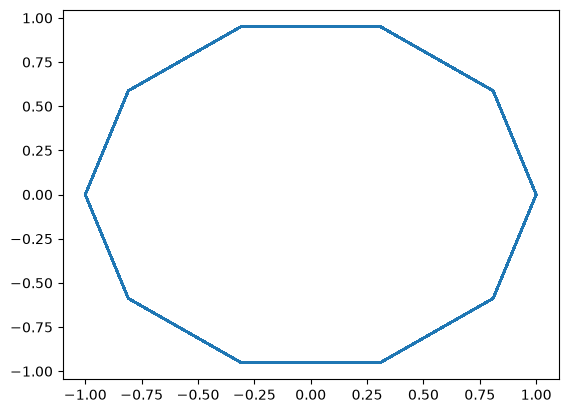

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math

fs= 1000 #sampling freq
fc= 100 #carrier wave

step_Size = 1/fs 
i=0

T =np.arange(0,1,step_Size) # steps of 0 to 1  at 1/fs so nyquist in complex
#iq =np.linspace(0,step_Size,1)
i_component = np.cos(2 * np.pi * fc * T)
q_component = np.sin(2 * np.pi * fc * T)
iq = i_component + 1j * q_component
#print(iq)

plt.plot(iq.real,iq.imag)

In [3]:
# offset the carrier wave

fo= 100#carrier wave

step_Size = 1/fs 
i=0

T =np.arange(0,1,step_Size) # steps of 0 to 1  at 1/fs so nyquist in complex
#iq =np.linspace(0,step_Size,1)
oi_component = np.cos(2 * np.pi * fo * T)
oq_component = np.sin(2 * np.pi * fo * T)
oiq = oi_component + 1j * oq_component

signal = iq * oiq

plt.plot(signal.real, signal.imag)

In [4]:


signal_fft_values = np.fft.fft(signal)
signal_fft_power = np.abs(signal_fft_values) ** 2

frequencies = np.fft.fftfreq(len(signal), d=step_Size)

plt.plot(frequencies, signal_fft_power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")

Text(21.722222222222214, 0.5, 'Power')

In [5]:
iq_fft_values = np.fft.fft(iq)
iq_fft_power = np.abs(iq_fft_values) ** 2

frequencies = np.fft.fftfreq(len(iq), d=step_Size)

plt.plot(frequencies, iq_fft_power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")


Text(21.722222222222214, 0.5, 'Power')

In [6]:
oiq_fft_values = np.fft.fft(oiq)
oiq_fft_power = np.abs(oiq_fft_values) ** 2

frequencies = np.fft.fftfreq(len(oiq), d=step_Size)

plt.plot(frequencies, oiq_fft_power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")


Text(21.722222222222214, 0.5, 'Power')

b0: 0.06739783593808155
b1: 0.1347956718761631
b2: 0.06739783593808155
a1: -0.12058033295248462
a2: -0.04355258824204524


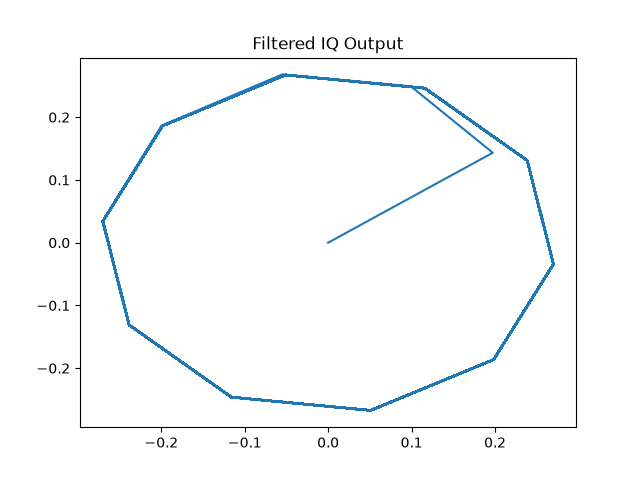

In [7]:


#filtering
#butterworth

#y[n] = b_0 x[n] + b_1 x[n-1] + b_2 x[n-2] - a_1 y[n-1] - a_2 y[n-2]
x=iq
order =2
y = np.zeros_like(x, dtype=complex) # empty output array

# prewarp
        #pi    carrier  sample
C = np.tan((3.14 * fc)/   fs)

#calculating denominator

D = pow(C,order) + math.sqrt(order)*C + 1

b0 = pow(C,order) / D
b1 = order*b0
b2 = b0
a1 = order * (pow(C, order) - 1) * b0
a2 = -(1 - math.sqrt(order) * C + pow(C, order)) * b0


print("b0:",b0)
print("b1:",b1)
print("b2:",b2)
print("a1:",a1)
print("a2:",a2)

for n in range(order,len(x)):
    y[n] = (b0 * x[n]
            + b1 * x[n-1]
            + b2 * x[n-2]
            - a1 * y[n-1]
            - a2 * y[n-2]
            )

plt.figure()
plt.plot(y.real, y.imag)
plt.title("Filtered IQ Output")

# Save as a high-resolution PNG or a scalable vector graphic (SVG)
plt.savefig("filtered_signal.png", dpi=300, bbox_inches="tight")
plt.savefig("filtered_signal.svg", bbox_inches="tight")  # Vector format

plt.show()